In [8]:
import os
import random
import numpy as np
import torch
import torchvision
import torchvision.transforms as transforms
from torchvision.datasets import OxfordIIITPet
from torch.utils.data import DataLoader
from sklearn.model_selection import train_test_split

SEED = 42

def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

set_seed(SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

raw_train = OxfordIIITPet(root='./data', split='trainval', target_types='category', download=True)
raw_test = OxfordIIITPet(root='./data', split='test', target_types='category', download=True)

cats = [c for c in raw_train.classes if c[0].isupper()][:5]
dogs = [c for c in raw_train.classes if c[0].islower()][:5]
sel_classes = cats + dogs

print(f"Selected 10 Classes: {sel_classes}")

class_idx = {c: i for i, c in enumerate(raw_train.classes)}
sel_idx = [class_idx[c] for c in sel_classes]
idx_map = {old: new for new, old in enumerate(sel_idx)}

all_imgs = raw_train._images + raw_test._images
all_labels = raw_train._labels + raw_test._labels

imgs = []
labels = []

for path, target in zip(all_imgs, all_labels):
    if target in idx_map:
        imgs.append(path)
        labels.append(idx_map[target])

print(f"Total filtered samples across 10 classes: {len(imgs)}")

idx = np.arange(len(labels))
train_idx, temp_idx, y_train, y_temp = train_test_split(
    idx, labels, test_size=0.30, stratify=labels, random_state=SEED
)
val_idx, test_idx, y_val, y_test = train_test_split(
    temp_idx, y_temp, test_size=0.50, stratify=y_temp, random_state=SEED
)

print(f"Dataset Split Sizes -> Train: {len(train_idx)}, Validation: {len(val_idx)}, Test: {len(test_idx)}")

weights = torchvision.models.ResNet18_Weights.IMAGENET1K_V1
mean = weights.transforms().mean
std = weights.transforms().std

train_aug = transforms.Compose([
    transforms.Resize(256),
    transforms.RandomResizedCrop(224, scale=(0.8, 1.0)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(degrees=15),
    transforms.ColorJitter(brightness=0.2, contrast=0.2),
    transforms.ToTensor(),
    transforms.Normalize(mean=mean, std=std),
])

train_no_aug = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=mean, std=std),
])

eval_transforms = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=mean, std=std),
])

class Oxford10Subset(torch.utils.data.Dataset):
    def __init__(self, samples, targets, indices, transform=None):
        self.samples = [samples[i] for i in indices]
        self.targets = [targets[i] for i in indices]
        self.transform = transform
        self.loader = torchvision.datasets.folder.default_loader

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, idx):
        path = self.samples[idx]
        target = self.targets[idx]
        img = self.loader(path)
        if self.transform is not None:
            img = self.transform(img)
        return img, target

train_ds_aug = Oxford10Subset(imgs, labels, train_idx, transform=train_aug)
train_ds_no_aug = Oxford10Subset(imgs, labels, train_idx, transform=train_no_aug)
val_ds = Oxford10Subset(imgs, labels, val_idx, transform=eval_transforms)
test_ds = Oxford10Subset(imgs, labels, test_idx, transform=eval_transforms)

BATCH_SIZE = 32
train_loader_aug = DataLoader(train_ds_aug, batch_size=BATCH_SIZE, shuffle=True, num_workers=2)
train_loader_no_aug = DataLoader(train_ds_no_aug, batch_size=BATCH_SIZE, shuffle=True, num_workers=2)
val_loader = DataLoader(val_ds, batch_size=BATCH_SIZE, shuffle=False, num_workers=2)
test_loader = DataLoader(test_ds, batch_size=BATCH_SIZE, shuffle=False, num_workers=2)

print("Data pipeline setup complete!")

Using device: cuda
Selected 10 Classes: ['Abyssinian', 'American Bulldog', 'American Pit Bull Terrier', 'Basset Hound', 'Beagle']
Total filtered samples across 10 classes: 998
Dataset Split Sizes -> Train: 698, Validation: 150, Test: 150
Data pipeline setup complete!


In [9]:
import time
import csv
import pandas as pd
import torch
import torch.nn as nn
import torch.optim as optim
from sklearn.metrics import f1_score

CSV_LOG_FILE = "metrics_log.csv"

with open(CSV_LOG_FILE, mode='w', newline='') as f:
    writer = csv.writer(f)
    writer.writerow([
        "Condition", "Model", "Trainable_Params", "Total_Params",
        "Learning_Rate", "Epochs_To_Converge", "Total_Time_Sec",
        "Best_Val_Loss", "Best_Val_Acc", "Test_Acc", "Test_Macro_F1"
    ])

def train_epoch(model, loader, criterion, optimizer, device):
    model.train()
    loss_sum, correct, total = 0.0, 0, 0
    for x, y in loader:
        x, y = x.to(device), y.to(device)
        optimizer.zero_grad()
        out = model(x)
        loss = criterion(out, y)
        loss.backward()
        optimizer.step()

        loss_sum += loss.item() * x.size(0)
        _, pred = out.max(1)
        correct += pred.eq(y).sum().item()
        total += y.size(0)
    return loss_sum / total, correct / total

@torch.no_grad()
def evaluate(model, loader, criterion, device):
    model.eval()
    loss_sum, correct, total = 0.0, 0, 0
    preds, targets = [], []

    for x, y in loader:
        x, y = x.to(device), y.to(device)
        out = model(x)
        loss = criterion(out, y)

        loss_sum += loss.item() * x.size(0)
        _, pred = out.max(1)
        correct += pred.eq(y).sum().item()
        total += y.size(0)

        preds.extend(pred.cpu().numpy())
        targets.extend(y.cpu().numpy())

    acc = correct / total
    f1 = f1_score(targets, preds, average='macro')
    return loss_sum / total, acc, f1, preds, targets

def run_experiment(cond, model, train_loader, val_loader, test_loader,
                   opt, lr, max_epochs=25, patience=4):

    criterion = nn.CrossEntropyLoss()
    model = model.to(device)

    train_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
    total_params = sum(p.numel() for p in model.parameters())
    print(f"\n=======================================================")
    print(f" Running Condition: {cond}")
    print(f" Trainable Params: {train_params:,} / {total_params:,}")
    print(f"=======================================================")

    best_loss = float('inf')
    best_weights = None
    wait = 0
    best_epoch = 0

    start = time.time()

    for epoch in range(1, max_epochs + 1):
        train_loss, train_acc = train_epoch(model, train_loader, criterion, opt, device)
        val_loss, val_acc, val_f1, _, _ = evaluate(model, val_loader, criterion, device)

        print(f"Epoch {epoch:02d}/{max_epochs:02d} | Train Loss: {train_loss:.4f} Acc: {train_acc:.4f} | Val Loss: {val_loss:.4f} Acc: {val_acc:.4f}")

        if val_loss < best_loss:
            best_loss = val_loss
            best_acc = val_acc
            best_weights = model.state_dict().copy()
            wait = 0
            best_epoch = epoch
        else:
            wait += 1
            if wait >= patience:
                print(f"--> Early stopping triggered at epoch {epoch}. Best epoch was {best_epoch}.")
                break

    total_time = time.time() - start

    model.load_state_dict(best_weights)
    test_loss, test_acc, test_f1, test_preds, test_targets = evaluate(model, test_loader, criterion, device)

    print(f"--> [TEST RESULTS] Accuracy: {test_acc:.4f} | Macro F1: {test_f1:.4f} | Runtime: {total_time:.2f}s")

    with open(CSV_LOG_FILE, mode='a', newline='') as f:
        writer = csv.writer(f)
        writer.writerow([
            cond, model.__class__.__name__, train_params, total_params,
            lr, best_epoch, round(total_time, 2),
            round(best_loss, 4), round(best_acc, 4),
            round(test_acc, 4), round(test_f1, 4)
        ])

    return model, test_preds, test_targets

set_seed(SEED)
model_b1 = torchvision.models.resnet18(weights=None)
model_b1.fc = nn.Linear(model_b1.fc.in_features, 10)
opt_b1 = optim.AdamW(model_b1.parameters(), lr=1e-3, weight_decay=1e-2)
model_b1, _, _ = run_experiment("B1", model_b1, train_loader_aug, val_loader, test_loader, opt_b1, "1e-3")

set_seed(SEED)
weights_resnet = torchvision.models.ResNet18_Weights.IMAGENET1K_V1
model_b2 = torchvision.models.resnet18(weights=weights_resnet)
for p in model_b2.parameters():
    p.requires_grad = False
model_b2.fc = nn.Linear(model_b2.fc.in_features, 10)
opt_b2 = optim.AdamW(model_b2.fc.parameters(), lr=1e-3, weight_decay=1e-2)
model_b2, _, _ = run_experiment("B2", model_b2, train_loader_aug, val_loader, test_loader, opt_b2, "1e-3")

set_seed(SEED)
model_b3 = torchvision.models.resnet18(weights=weights_resnet)
for p in model_b3.parameters():
    p.requires_grad = False
for p in model_b3.layer4.parameters():
    p.requires_grad = True
model_b3.fc = nn.Linear(model_b3.fc.in_features, 10)
opt_b3 = optim.AdamW([
    {"params": model_b3.layer4.parameters(), "lr": 1e-4},
    {"params": model_b3.fc.parameters(), "lr": 1e-3}
], weight_decay=1e-2)
model_b3, best_test_preds, best_test_targets = run_experiment("B3", model_b3, train_loader_aug, val_loader, test_loader, opt_b3, "layer4:1e-4, fc:1e-3")

set_seed(SEED)
model_b4 = torchvision.models.resnet18(weights=weights_resnet)
for p in model_b4.parameters():
    p.requires_grad = False
model_b4.fc = nn.Linear(model_b4.fc.in_features, 10)
opt_b4 = optim.AdamW(model_b4.fc.parameters(), lr=1e-3, weight_decay=1e-2)
model_b4, _, _ = run_experiment("B4_NoAug", model_b4, train_loader_no_aug, val_loader, test_loader, opt_b4, "1e-3")

set_seed(SEED)
weights_eff = torchvision.models.EfficientNet_B0_Weights.IMAGENET1K_V1
model_b5 = torchvision.models.efficientnet_b0(weights=weights_eff)
for p in model_b5.parameters():
    p.requires_grad = False
num_ftrs = model_b5.classifier[1].in_features
model_b5.classifier[1] = nn.Linear(num_ftrs, 10)
opt_b5 = optim.AdamW(model_b5.classifier[1].parameters(), lr=1e-3, weight_decay=1e-2)
model_b5, _, _ = run_experiment("B5_EfficientNetB0", model_b5, train_loader_aug, val_loader, test_loader, opt_b5, "1e-3")

print("\n--- ALL EXPERIMENTS COMPLETED ---")
print("Raw metrics saved to 'metrics_log.csv'. Displaying log summary:\n")
df_results = pd.read_csv(CSV_LOG_FILE)
display(df_results)


 Running Condition: B1
 Trainable Params: 11,181,642 / 11,181,642
Epoch 01/25 | Train Loss: 1.9479 Acc: 0.2636 | Val Loss: 4.0477 Acc: 0.3000
Epoch 02/25 | Train Loss: 1.5140 Acc: 0.3166 | Val Loss: 1.5097 Acc: 0.2867
Epoch 03/25 | Train Loss: 1.4732 Acc: 0.3682 | Val Loss: 1.6913 Acc: 0.2533
Epoch 04/25 | Train Loss: 1.4184 Acc: 0.4069 | Val Loss: 1.6042 Acc: 0.2933
Epoch 05/25 | Train Loss: 1.3338 Acc: 0.4298 | Val Loss: 1.6848 Acc: 0.3400
Epoch 06/25 | Train Loss: 1.3126 Acc: 0.4556 | Val Loss: 1.5562 Acc: 0.3667
--> Early stopping triggered at epoch 6. Best epoch was 2.
--> [TEST RESULTS] Accuracy: 0.3600 | Macro F1: 0.3145 | Runtime: 45.20s

 Running Condition: B2
 Trainable Params: 5,130 / 11,181,642
Epoch 01/25 | Train Loss: 1.4481 Acc: 0.4341 | Val Loss: 0.8537 Acc: 0.7933
Epoch 02/25 | Train Loss: 0.7598 Acc: 0.8080 | Val Loss: 0.5775 Acc: 0.8533
Epoch 03/25 | Train Loss: 0.5394 Acc: 0.8582 | Val Loss: 0.4442 Acc: 0.8800
Epoch 04/25 | Train Loss: 0.4483 Acc: 0.8954 | Val Loss

,Condition,Model,Trainable_Params,Total_Params,Learning_Rate,Epochs_To_Converge,Total_Time_Sec,Best_Val_Loss,Best_Val_Acc,Test_Acc,Test_Macro_F1
0,B1,ResNet,11181642,11181642,1e-3,2,45.20,1.5097,0.2867,0.3600,0.3145
1,B2,ResNet,5130,11181642,1e-3,23,181.22,0.2491,0.9133,0.8867,0.8883
2,B3,ResNet,8398858,11181642,"layer4:1e-4, fc:1e-3",6,72.00,0.2346,0.9267,0.9200,0.9204
3,B4_NoAug,ResNet,5130,11181642,1e-3,25,114.99,0.2441,0.9200,0.9000,0.9009
4,B5_EfficientNetB0,EfficientNet,12810,4020358,1e-3,24,180.19,0.3048,0.9000,0.8667,0.8658


Extracting misclassified samples from test set...
Successfully extracted 8 misclassified test samples!


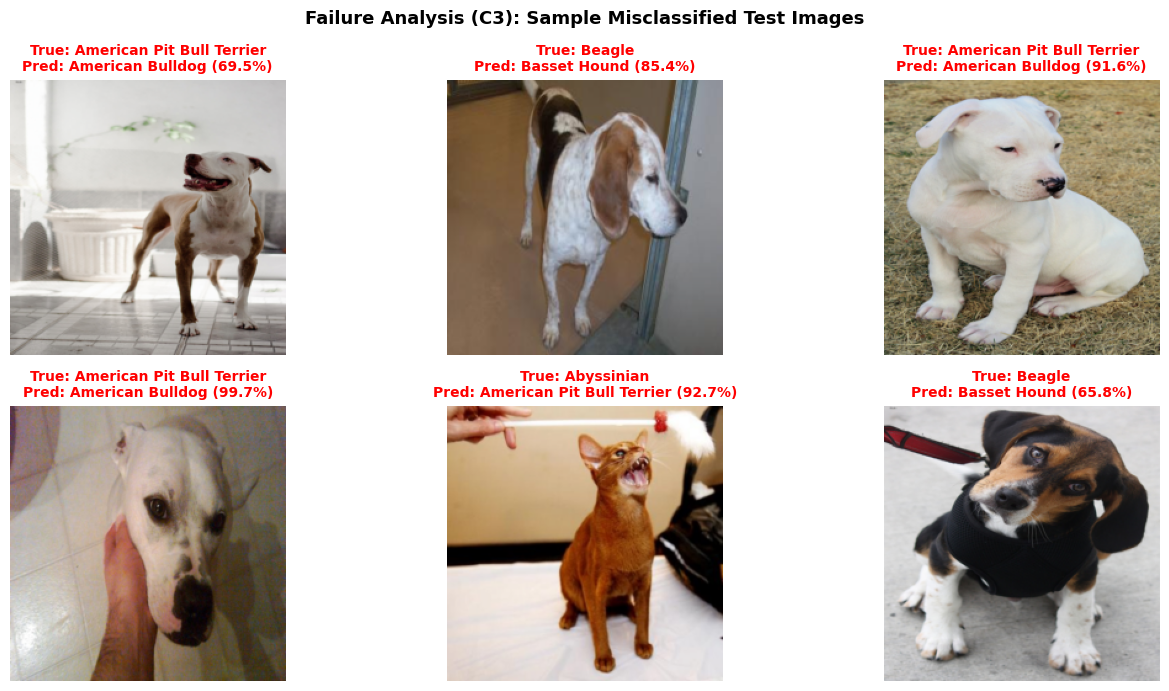

In [10]:
import matplotlib.pyplot as plt
import numpy as np

model_b3.eval()
misclassified = []

class_names = SELECTED_CLASSES

print("Extracting misclassified samples from test set...")

with torch.no_grad():
    for x, y in test_loader:
        x, y = x.to(device), y.to(device)
        out = model_b3(x)
        probs = torch.softmax(out, dim=1)
        conf, pred = probs.max(1)

        for i in range(x.size(0)):
            if pred[i] != y[i]:
                misclassified.append({
                    "image": x[i].cpu().numpy(),
                    "true_label": class_names[y[i].item()],
                    "pred_label": class_names[pred[i].item()],
                    "confidence": conf[i].item()
                })

        if len(misclassified) >= 6:
            break

print(f"Successfully extracted {len(misclassified)} misclassified test samples!")

if len(misclassified) > 0:
    plt.figure(figsize=(14, 7))
    n = min(6, len(misclassified))

    for i in range(n):
        sample = misclassified[i]
        plt.subplot(2, 3, i + 1)

        img = sample["image"].transpose((1, 2, 0))
        img = imagenet_std * img + imagenet_mean
        img = np.clip(img, 0, 1)

        plt.imshow(img)
        plt.title(f"True: {sample['true_label']}\nPred: {sample['pred_label']} ({sample['confidence']*100:.1f}%)",
                  color="red", fontsize=10, fontweight="bold")
        plt.axis("off")

    plt.suptitle("Failure Analysis (C3): Sample Misclassified Test Images", fontsize=13, fontweight="bold")
    plt.tight_layout()
    plt.savefig("failure_analysis_samples.png", dpi=200)
    plt.show()
else:
    print("No misclassified samples found!")